<a href="https://colab.research.google.com/github/rxk1b/WIX1002-FOP/blob/main/WIA1007_Tutorial3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial 03 – Tidy Data & Data Characteristics
**Course:** WIA1007 Introduction to Data Science (OCC 2)
**Name:** Mahathir Imam Rakib

**Dataset:** *Students Performance in Exams* (Kaggle) – https://www.kaggle.com/datasets/spscientist/students-performance-in-exams
Each row is one student. The columns describe the student's background and their scores in three exams (math, reading, writing).

## 1. Load a real dataset and visualise some of it
**How to load:** download `StudentsPerformance.csv` from Kaggle, then in Colab click the **folder icon** on the left and drag the file in.
(Alternative: put it in Google Drive, run the Drive cell below, then right-click the file → *Copy path* and paste it into `path`.)

In [1]:
# Option 2 (optional): use Google Drive so the file stays after the session ends
# from google.colab import drive
# drive.mount('/content/drive')

In [2]:
import pandas as pd

path = "/content/StudentsPerformance.csv"   # change this if your file is somewhere else
df = pd.read_csv(path)

# Show the first 5 rows
display(df.head())

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [3]:
# Show the last 5 rows
display(df.tail())

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


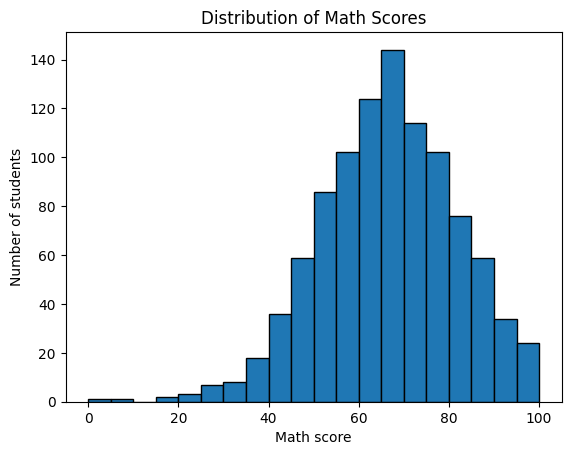

In [4]:
# Bonus: a simple chart of the math scores
import matplotlib.pyplot as plt

df["math score"].plot(kind="hist", bins=20, edgecolor="black")
plt.title("Distribution of Math Scores")
plt.xlabel("Math score")
plt.ylabel("Number of students")
plt.show()

## 2. Is the data good? Does it have enough samples?

In [5]:
print("Rows and columns:", df.shape)
print("Duplicated rows:", df.duplicated().sum())

Rows and columns: (1000, 8)
Duplicated rows: 0


**Answer:** The dataset has **1000 rows** (students) and **8 columns**, with no duplicated rows. It is a *tidy* table: one student per row and one variable per column, so it is easy to work with.

1000 samples is a reasonable size for a beginner analysis and for training a simple machine-learning model (e.g. predicting a student's math score). It is not very large, so a complex model could overfit. Overall, the data is good for this tutorial.

## 3. How many features does it have? Is it enough?

In [6]:
print("All columns:", df.columns.tolist())
print("Total columns:", len(df.columns))

target = "math score"
features = df.drop(columns=[target])
print("Number of features:", len(features.columns))
print("Features:", features.columns.tolist())

All columns: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']
Total columns: 8
Number of features: 7
Features: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'reading score', 'writing score']


**Answer:** There are 8 columns. One of them, `math score`, is the **target**, so there are **7 features**: gender, race/ethnicity, parental level of education, lunch, test preparation course, reading score and writing score.

7 features is enough for a simple analysis, because they cover the student's background (5 categorical columns) and their other exam results (2 numeric columns). It does not include things like study hours or attendance, which could make predictions better.

## 4. How many samples / observations does it have? Is it enough?

In [7]:
print("Number of samples (rows):", len(df))

Number of samples (rows): 1000


**Answer:** There are **1000 samples**. Samples, observations and rows mean the same thing here: each row is one student. This is enough for basic analysis and a simple model, but more data (for example, from several schools or years) would make the results more reliable.

## 5. What data types does the dataset consist of?

In [8]:
print(df.dtypes)
print()
df.info()

gender                         object
race/ethnicity                 object
parental level of education    object
lunch                          object
test preparation course        object
math score                      int64
reading score                   int64
writing score                   int64
dtype: object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes

**Answer:**
| Column | Python type | Type of data |
|---|---|---|
| gender | object (text) | Qualitative – nominal |
| race/ethnicity | object (text) | Qualitative – nominal (groups A–E) |
| parental level of education | object (text) | Qualitative – **ordinal** (has an order: high school → … → master's degree) |
| lunch | object (text) | Qualitative – nominal (standard / free-reduced) |
| test preparation course | object (text) | Qualitative – nominal (completed / none) |
| math score | int64 | Quantitative – discrete (whole numbers 0–100) |
| reading score | int64 | Quantitative – discrete |
| writing score | int64 | Quantitative – discrete |

So the dataset has **5 categorical (object) columns** and **3 numeric (int64) columns**.

In [9]:
# Summary statistics of the numeric columns
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


## 6. How many columns have null values? If yes, which columns and which rows?

In [10]:
missing = df.isnull().sum()
print("Missing values in each column:")
print(missing)
print()
print("Number of columns with missing values:", (missing > 0).sum())

Missing values in each column:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Number of columns with missing values: 0


**Answer:** Every column shows **0** null values, so **no columns** have null values and there are no rows to list.

## 7. Which column is the feature, which is the target output?

In [11]:
print("Target:", target)
print("Features:", features.columns.tolist())
print("Unique values of the target (first 10):", sorted(df[target].unique().tolist())[:10])

Target: math score
Features: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'reading score', 'writing score']
Unique values of the target (first 10): [0, 8, 18, 19, 22, 23, 24, 26, 27, 28]


**Answer:** The question I want to answer is *"What math score will a student get?"*, so the **target** is **`math score`**.
The **features** are the other 7 columns: gender, race/ethnicity, parental level of education, lunch, test preparation course, reading score and writing score.

The dataset has no ID column, so there is nothing to drop for privacy reasons. (Another valid choice of target is a pass/fail column created from the scores.)

## 8. Does it have missing values? If yes, which column, which row?

In [12]:
rows_missing = df[df.isnull().any(axis=1)]
print("Number of rows with missing values:", len(rows_missing))
display(rows_missing.head(10))

Number of rows with missing values: 0


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score


**Answer:** **No.** There are **0 rows** with missing values (the table above is empty), so this dataset does not need any cleaning for missing data. A dataset with no missing values is rare in real life, so this one is easy to work with.

## 9. What kind of questions can be asked? Does the dataset suit the question?
**Questions this dataset can answer:**
1. Does completing the **test preparation course** improve students' scores?
2. Do students with **standard lunch** score higher than students with free/reduced lunch?
3. Does **parental level of education** relate to students' scores?
4. Can we **predict a student's math score** from the other columns?

Below I test Question 1.

In [13]:
# Average score for students who did vs did not complete the test preparation course
df.groupby("test preparation course")[["math score", "reading score", "writing score"]].mean().round(1)

,math score,reading score,writing score
test preparation course,,,
completed,69.7,73.9,74.4
none,64.1,66.5,64.5


**Answer:** Students who **completed** the test preparation course have higher average scores in all three subjects than students who did not, so the course appears to help.

**Does the dataset suit the question?** Yes, because it has a column for the test preparation course and columns for the scores, with 1000 students and no missing values.
**Limitation:** it only shows a relationship, not proof of cause. For example, students who choose to take the course may already be more motivated. The dataset does not have columns like study hours or attendance, so some questions cannot be answered with it.